Dataset loaded successfully!
Dataset shape: (210, 7)


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Kernel_Groove
15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 210 entries, 15.26 to 12.3
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area           210 non-null    float64
 1   Perimeter      210 non-null    float64
 2   Compactness    210 non-null    float64
 3   Kernel_Length  210 non-null    float64
 4   Kernel_Width   210 non-null    float64
 5   Asymmetry      210 non-null    float64
 6   Kernel_Groove  210 non-null    int64  
dtypes: float64(6), int64(1)
memory usage: 13.1 KB

Missing Values:
Area             0
Perimeter        0
Compactness      0
Kernel_Length    0
Kernel_Width     0
Asymmetry        0
Kernel_Groove    0
dtype: int64

Statistical Summary:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Kernel_Groove
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000



Data standardization completed!

Cluster Distribution:
Cluster
0    69
1    70
2    71
Name: count, dtype: int64

Silhouette Score: 0.48266139973638683


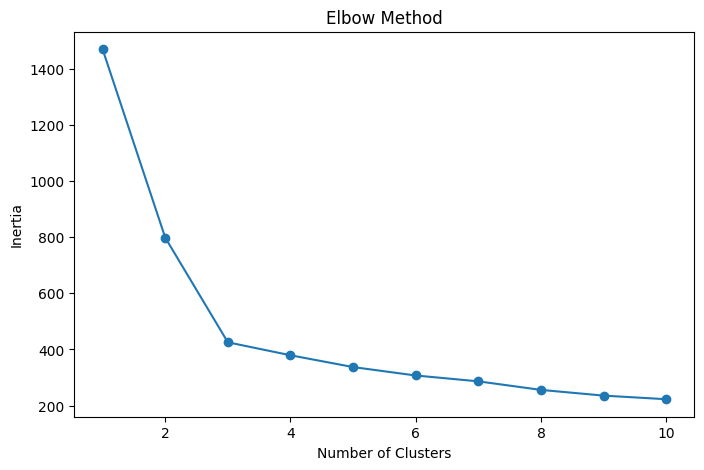

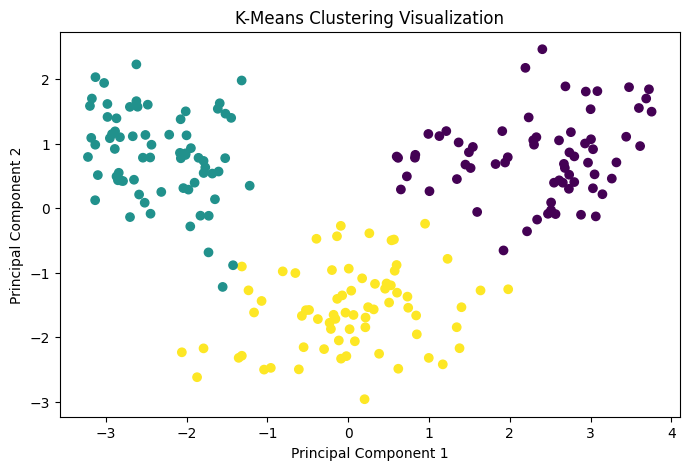


Explained Variance Ratio:
[0.6012819 0.2403617]

Total Explained Variance: 0.8416435954135741


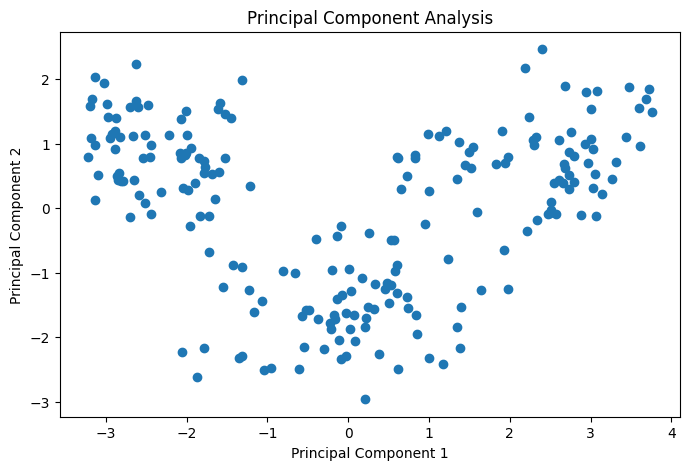


Unsupervised Learning completed successfully!


In [1]:
# MACHINE LEARNING: UNSUPERVISED LEARNING
# K-Means Clustering and PCA

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 2. Download Seeds dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"

columns = [
    "Area", "Perimeter", "Compactness",
    "Kernel_Length", "Kernel_Width",
    "Asymmetry", "Kernel_Groove"
]

df = pd.read_csv(url, sep=r"\s+", header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

# 3. Explore dataset
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

# 4. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("\nData standardization completed!")

# 5. K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)
df["Cluster"] = clusters

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

# 6. Evaluate clustering
score = silhouette_score(X_scaled, clusters)
print("\nSilhouette Score:", score)

# 7. Elbow Method
inertia_values = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# 8. Visualize K-Means clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering Visualization")
plt.show()

# 9. PCA Explained Variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Explained Variance:",
    sum(pca.explained_variance_ratio_)
)

# 10. PCA visualization
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Principal Component Analysis")
plt.show()

print("\nUnsupervised Learning completed successfully!")

# Conclusion

In this project, we implemented unsupervised machine learning techniques using the Seeds dataset.

The following techniques were explored:

1. K-Means Clustering
2. Elbow Method
3. Principal Component Analysis (PCA)

The dataset was loaded and standardized before applying machine learning algorithms.

K-Means Clustering was used to group similar data points into three clusters. The Elbow Method was used to study the appropriate number of clusters.

PCA was applied to reduce the dimensionality of the dataset and visualize it using two principal components.

The silhouette score was used to evaluate clustering performance.

Through this project, we gained practical knowledge of unsupervised learning, clustering, dimensionality reduction, and data visualization.